# Day 068 | CNN — Fundamentals
## 100 Days of ML for Geotechnical Engineering

| | |
|---|---|
| **Author** | Ripon Chandra Malo |
| **Phase** | 4 — Deep Learning |
| **Topic** | 1D Convolutional Neural Networks |
| **Tools** | PyTorch, NumPy, Matplotlib |
| **Geo Problem** | Classifying CPT depth profiles (sand / clay / mixed) using 1D convolution |

---

## Concept Overview

| Concept | Description | CPT Analogy |
|---|---|---|
| Conv1d(in, out, kernel) | Slides a learnable filter over a 1D sequence | Filter detects layer transitions in the qc profile |
| Kernel / Filter | Small weight array that computes a dot product at each position | 7-point window examining 7 depth readings at once |
| Stride | How many steps the filter moves per application | Stride=2 skips alternate depths |
| Padding | Adding zeros at sequence edges | Keeps output length = input length when padding=kernel//2 |
| ReLU | Keeps only positive activations | Highlights sharp qc jumps (layer boundaries) |
| MaxPool1d | Takes max value in each pooling window | Retains the strongest detected feature in a depth interval |
| Feature map | Output of one filter across the full depth | Each of the 16 filters learns a different profile pattern |
| Flatten | Converts feature maps to 1D vector for FC layers | Summarises entire profile into a fixed-length descriptor |

---

## Geotechnical Problem Framing

**Cone Penetration Test (CPT)** produces a depth profile of tip resistance **qc (MPa)** at every 2 cm. The shape of the profile reveals the soil stratigraphy:

- **Sand**: high qc (~10–20 MPa), relatively uniform
- **Clay**: low qc (~0.5–3 MPa), smooth
- **Mixed**: alternating layers — high-frequency transitions

Traditional classification requires a geotechnical engineer to manually inspect each profile. A 1D CNN can automatically detect layer-transition patterns and classify the soil type from the raw depth trace — the same way a 2D CNN detects edges in images.

**Input**: qc profile of length 64 (depths: 0–6.4 m at 0.1 m spacing)  
**Output**: soil class (0=sand, 1=clay, 2=mixed)

---
## Part 1 | Setup & Synthetic CPT Profiles

In [1]:
# ─────────────────────────────────────────────────────────
# PART 1 — Setup & Synthetic CPT Profile Generator
# ─────────────────────────────────────────────────────────
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)

PROFILE_LEN = 64    # number of depth readings per CPT
N_SAMPLES   = 150   # total CPT profiles
N_CLASSES   = 3     # sand=0, clay=1, mixed=2
depths      = np.linspace(0, 6.4, PROFILE_LEN)  # metres

def generate_cpt_profile(soil_class):
    """Generate a synthetic CPT qc profile for a given soil class."""
    if soil_class == 0:   # SAND: high qc, low variability
        base  = np.random.uniform(8, 18)
        noise = np.random.normal(0, 1.5, PROFILE_LEN)
        qc    = np.clip(base + noise, 4, 25)

    elif soil_class == 1:  # CLAY: low qc, smooth
        base  = np.random.uniform(0.5, 3.0)
        trend = np.linspace(0, np.random.uniform(0.5, 1.5), PROFILE_LEN)  # slight increase
        noise = np.random.normal(0, 0.2, PROFILE_LEN)
        qc    = np.clip(base + trend + noise, 0.3, 5)

    else:                  # MIXED: alternating sand and clay layers
        qc = np.zeros(PROFILE_LEN)
        idx = 0
        is_sand = np.random.rand() > 0.5
        while idx < PROFILE_LEN:
            layer_len = np.random.randint(4, 12)
            end = min(idx + layer_len, PROFILE_LEN)
            if is_sand:
                qc[idx:end] = np.random.uniform(8, 18) + np.random.normal(0, 1.0, end - idx)
            else:
                qc[idx:end] = np.random.uniform(0.5, 3.0) + np.random.normal(0, 0.2, end - idx)
            idx    = end
            is_sand = not is_sand
        qc = np.clip(qc, 0.3, 25)

    return qc.astype(np.float32)

# Generate dataset — 50 per class
profiles, labels = [], []
for cls in range(N_CLASSES):
    for _ in range(N_SAMPLES // N_CLASSES):
        profiles.append(generate_cpt_profile(cls))
        labels.append(cls)

profiles = np.array(profiles)          # (150, 64)
labels   = np.array(labels)            # (150,)

# Shuffle
perm     = np.random.permutation(N_SAMPLES)
profiles, labels = profiles[perm], labels[perm]

print(f"Dataset: {profiles.shape} profiles, {labels.shape} labels")
print(f"Class distribution: {np.bincount(labels)}")
print(f"qc range: {profiles.min():.2f} — {profiles.max():.2f} MPa")

Dataset: (150, 64) profiles, (150,) labels
Class distribution: [50 50 50]
qc range: 0.30 — 21.47 MPa


---
## Part 2 | Visualising CPT Profiles

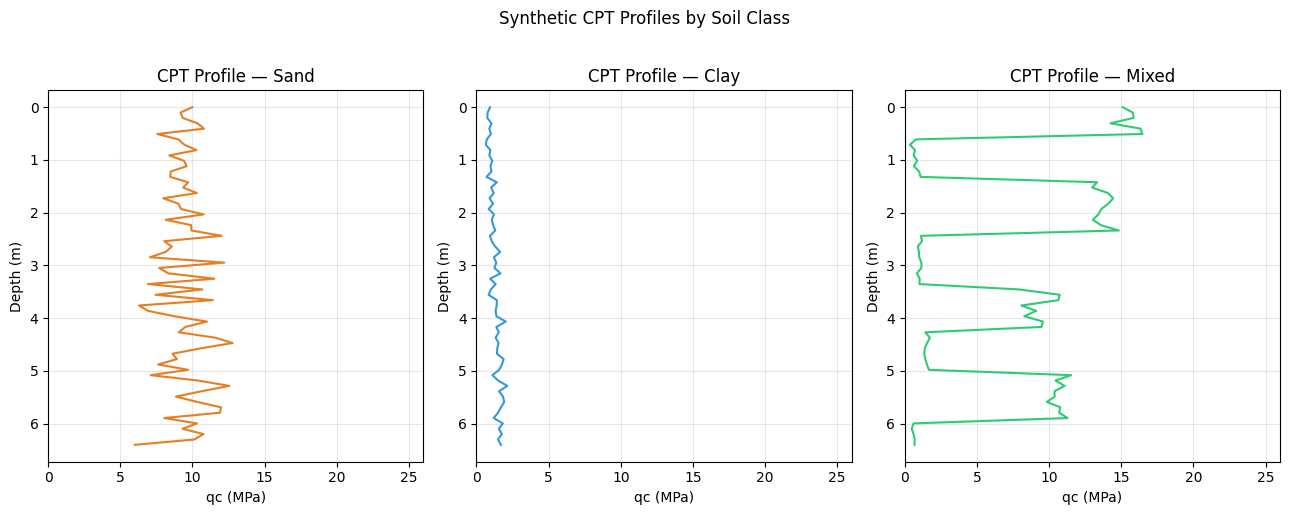

Note: the CNN must learn to distinguish these pattern shapes automatically.
  Sand  → consistently high qc
  Clay  → consistently low qc with slight depth trend
  Mixed → rapid alternations between high and low qc


In [2]:
# ─────────────────────────────────────────────────────────
# PART 2 — Visualise One Profile Per Soil Class
# ─────────────────────────────────────────────────────────
class_names = ['Sand', 'Clay', 'Mixed']
colors      = ['#e67e22', '#3498db', '#2ecc71']

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
for cls in range(N_CLASSES):
    sample = profiles[labels == cls][0]
    ax = axes[cls]
    ax.plot(sample, depths, color=colors[cls], lw=1.5)
    ax.invert_yaxis()
    ax.set_xlabel('qc (MPa)')
    ax.set_ylabel('Depth (m)')
    ax.set_title(f'CPT Profile — {class_names[cls]}')
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, 26)

plt.suptitle('Synthetic CPT Profiles by Soil Class', y=1.02)
plt.tight_layout()
plt.show()

print("Note: the CNN must learn to distinguish these pattern shapes automatically.")
print("  Sand  → consistently high qc")
print("  Clay  → consistently low qc with slight depth trend")
print("  Mixed → rapid alternations between high and low qc")

---
## Part 3 | 1D Convolution Concept

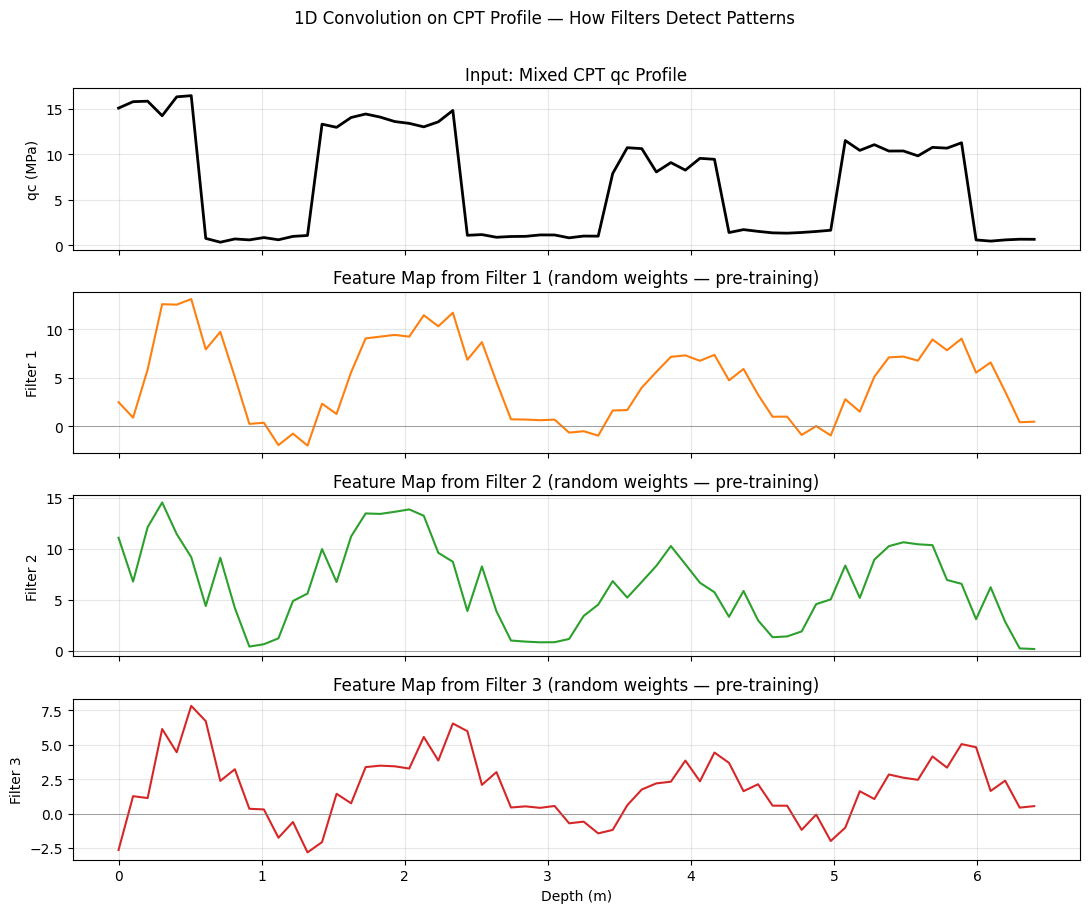

Each filter produces a different 'response curve' along the depth axis.
After training, some filters will fire strongly at sand-clay transitions,
others at sustained high-qc zones — automatically learned from data.


In [3]:
# ─────────────────────────────────────────────────────────
# PART 3 — Visualising a Conv1d Filter on a CPT Profile
# ─────────────────────────────────────────────────────────

# Create a single Conv1d layer (1 input channel, 3 output channels, kernel=7)
conv_demo = nn.Conv1d(in_channels=1, out_channels=3, kernel_size=7, padding=3)

# Use the first mixed profile
mixed_idx    = np.where(labels == 2)[0][0]
mixed_sample = torch.tensor(profiles[mixed_idx]).view(1, 1, PROFILE_LEN)  # (B, C, L)

with torch.no_grad():
    feature_maps = conv_demo(mixed_sample).squeeze(0)   # (3, 64)

fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)

axes[0].plot(depths, mixed_sample.squeeze().numpy(), color='black', lw=2)
axes[0].set_ylabel('qc (MPa)')
axes[0].set_title('Input: Mixed CPT qc Profile')
axes[0].grid(True, alpha=0.3)

filter_colors = ['C1', 'C2', 'C3']
for i in range(3):
    axes[i+1].plot(depths, feature_maps[i].numpy(), color=filter_colors[i], lw=1.5)
    axes[i+1].set_ylabel(f'Filter {i+1}')
    axes[i+1].set_title(f'Feature Map from Filter {i+1} (random weights — pre-training)')
    axes[i+1].grid(True, alpha=0.3)
    axes[i+1].axhline(0, color='gray', lw=0.5)

axes[-1].set_xlabel('Depth (m)')
plt.suptitle('1D Convolution on CPT Profile — How Filters Detect Patterns', y=1.01)
plt.tight_layout()
plt.show()

print("Each filter produces a different 'response curve' along the depth axis.")
print("After training, some filters will fire strongly at sand-clay transitions,")
print("others at sustained high-qc zones — automatically learned from data.")

---
## Part 4 | Stride, Padding and MaxPool1d

In [4]:
# ─────────────────────────────────────────────────────────
# PART 4 — Effect of Stride, Padding, and MaxPool1d
# ─────────────────────────────────────────────────────────

x_demo = mixed_sample  # (1, 1, 64)

# No padding, stride=1 -> output shorter than input
c_no_pad  = nn.Conv1d(1, 1, kernel_size=7, stride=1, padding=0)
# With padding=3, stride=1 -> same length
c_same    = nn.Conv1d(1, 1, kernel_size=7, stride=1, padding=3)
# Stride=2 -> halves the length
c_stride2 = nn.Conv1d(1, 1, kernel_size=7, stride=2, padding=3)
# MaxPool1d(2) -> also halves the length
pool2     = nn.MaxPool1d(kernel_size=2)

with torch.no_grad():
    out_no_pad  = c_no_pad(x_demo)
    out_same    = c_same(x_demo)
    out_stride2 = c_stride2(x_demo)
    out_pool    = pool2(c_same(x_demo))

print("Input length:                     ", x_demo.shape[-1])
print("Conv1d(k=7, stride=1, pad=0):     ", out_no_pad.shape[-1],  "← shorter (lost 6 steps)")
print("Conv1d(k=7, stride=1, pad=3):     ", out_same.shape[-1],    "← same length")
print("Conv1d(k=7, stride=2, pad=3):     ", out_stride2.shape[-1], "← halved (skip one step)")
print("Conv1d(same) + MaxPool1d(2):      ", out_pool.shape[-1],    "← halved (pooling)")

print()
print("Geotechnical interpretation:")
print("  - Padding=3 preserves the start/end of the CPT profile.")
print("  - MaxPool keeps the strongest signal in each 2-reading window.")
print("  - After 2 MaxPool layers: 64 -> 32 -> 16 (still captures stratigraphy).")

Input length:                      64
Conv1d(k=7, stride=1, pad=0):      58 ← shorter (lost 6 steps)
Conv1d(k=7, stride=1, pad=3):      64 ← same length
Conv1d(k=7, stride=2, pad=3):      32 ← halved (skip one step)
Conv1d(same) + MaxPool1d(2):       32 ← halved (pooling)

Geotechnical interpretation:
  - Padding=3 preserves the start/end of the CPT profile.
  - MaxPool keeps the strongest signal in each 2-reading window.
  - After 2 MaxPool layers: 64 -> 32 -> 16 (still captures stratigraphy).


---
## Part 5 | CNN Architecture for CPT Classification

In [5]:
# ─────────────────────────────────────────────────────────
# PART 5 — CPT Classifier CNN Architecture
# ─────────────────────────────────────────────────────────

class CPTClassifierCNN(nn.Module):
    """
    1D CNN for CPT profile soil classification.

    Architecture:
      Conv1d(1, 16, 7, pad=3)  -> ReLU -> MaxPool1d(2)   [64 -> 32]
      Conv1d(16, 32, 5, pad=2) -> ReLU -> MaxPool1d(2)   [32 -> 16]
      Flatten                                             [32 * 16 = 512]
      Linear(512, 64) -> ReLU
      Linear(64, 3)                                       [3 soil classes]
    """
    def __init__(self):
        super().__init__()
        self.conv_block1 = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=7, padding=3),
            nn.ReLU(),
            nn.MaxPool1d(2)
        )
        self.conv_block2 = nn.Sequential(
            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 16, 64),
            nn.ReLU(),
            nn.Linear(64, 3)
        )

    def forward(self, x):
        # x: (batch, 1, 64)
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        return self.classifier(x)

model = CPTClassifierCNN()
total_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nTotal trainable parameters: {total_params:,}")

# Verify forward pass shape
dummy = torch.zeros(8, 1, 64)
out   = model(dummy)
print(f"\nInput shape:  {dummy.shape}")
print(f"Output shape: {out.shape}  (8 samples, 3 class logits)")

CPTClassifierCNN(
  (conv_block1): Sequential(
    (0): Conv1d(1, 16, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block2): Sequential(
    (0): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=512, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=3, bias=True)
  )
)

Total trainable parameters: 35,747

Input shape:  torch.Size([8, 1, 64])
Output shape: torch.Size([8, 3])  (8 samples, 3 class logits)


---
## Part 6 | Training the CPT CNN

In [6]:
# ─────────────────────────────────────────────────────────
# PART 6 — Data Preparation and Training Loop
# ─────────────────────────────────────────────────────────

# Tensors: profiles -> (N, 1, 64) for Conv1d (batch, channels, length)
X_tensor = torch.tensor(profiles, dtype=torch.float32).unsqueeze(1)  # (150, 1, 64)
y_tensor = torch.tensor(labels,   dtype=torch.long)                  # (150,)

# Normalise by mean/std of the full dataset
X_mean   = X_tensor.mean()
X_std    = X_tensor.std()
X_tensor = (X_tensor - X_mean) / X_std

# Train / test split (120 / 30)
split    = 120
perm_idx = torch.randperm(N_SAMPLES)
tr_idx, te_idx = perm_idx[:split], perm_idx[split:]

tr_loader = DataLoader(TensorDataset(X_tensor[tr_idx], y_tensor[tr_idx]),
                       batch_size=16, shuffle=True)
te_loader = DataLoader(TensorDataset(X_tensor[te_idx], y_tensor[te_idx]),
                       batch_size=16)

# Training
torch.manual_seed(0)
model     = CPTClassifierCNN()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
EPOCHS    = 80

tr_loss_hist, tr_acc_hist = [], []

for epoch in range(EPOCHS):
    model.train()
    total_loss, correct = 0.0, 0
    for xb, yb in tr_loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss   = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
        correct    += (logits.argmax(1) == yb).sum().item()
    tr_loss_hist.append(total_loss / split)
    tr_acc_hist.append(correct / split)

print(f"Final training accuracy: {tr_acc_hist[-1]*100:.1f}%")

Final training accuracy: 100.0%


---
## Part 7 | Evaluation & Learned Filter Visualization

Test accuracy: 100.0%  (30/30 correct)
  Sand  : 100%
  Clay  : 100%
  Mixed : 100%


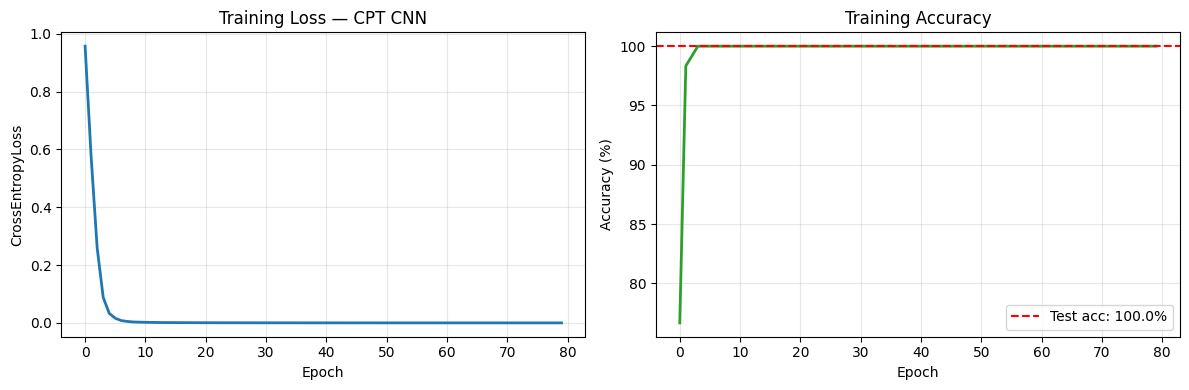

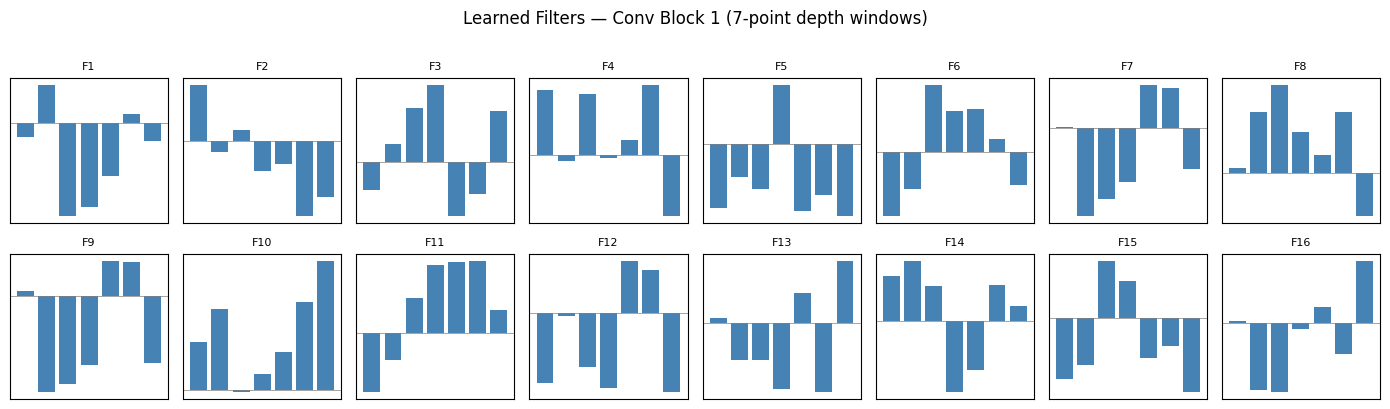

In [7]:
# ─────────────────────────────────────────────────────────
# PART 7 — Evaluation and Learned Filter Visualisation
# ─────────────────────────────────────────────────────────

# Test accuracy
model.eval()
correct = 0
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in te_loader:
        preds = model(xb).argmax(1)
        correct += (preds == yb).sum().item()
        all_preds.extend(preds.numpy())
        all_labels.extend(yb.numpy())

test_acc = correct / len(te_idx)
print(f"Test accuracy: {test_acc*100:.1f}%  ({correct}/{len(te_idx)} correct)")

# Per-class accuracy
all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)
for cls, name in enumerate(class_names):
    mask = all_labels == cls
    if mask.sum() > 0:
        cls_acc = (all_preds[mask] == cls).mean() * 100
        print(f"  {name:6s}: {cls_acc:.0f}%")

# Training curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(tr_loss_hist, lw=2, color='C0')
ax1.set_title('Training Loss — CPT CNN'); ax1.set_xlabel('Epoch')
ax1.set_ylabel('CrossEntropyLoss'); ax1.grid(True, alpha=0.3)

ax2.plot([a*100 for a in tr_acc_hist], lw=2, color='C2')
ax2.axhline(test_acc*100, color='red', linestyle='--', label=f'Test acc: {test_acc*100:.1f}%')
ax2.set_title('Training Accuracy'); ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)'); ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

# Visualise learned filters from Conv block 1
filters = model.conv_block1[0].weight.data.squeeze(1)  # (16, 7)
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.bar(range(7), filters[i].numpy(), color='steelblue')
    ax.set_title(f'F{i+1}', fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
    ax.axhline(0, color='gray', lw=0.5)
plt.suptitle('Learned Filters — Conv Block 1 (7-point depth windows)', y=1.01)
plt.tight_layout()
plt.show()

---
## Practice Exercises

1. **Kernel size experiment** — Change the first Conv1d kernel from 7 to 3 and 15. How does the field of view (receptive field) change? Does test accuracy improve?
2. **Add a third conv block** — Insert `Conv1d(32, 64, 3, padding=1) -> ReLU -> MaxPool1d(2)` before the classifier. Recalculate the flatten size and retrain.
3. **Noise robustness** — Add Gaussian noise (σ=2 MPa) to test profiles. How much does accuracy drop? Add Dropout after each conv block and compare.
4. **Feature map analysis** — After training, pass a sand, clay, and mixed profile through `conv_block1` and plot the 16 feature maps. Which filters respond most differently?
5. **Regression variant** — Instead of classifying soil type, use the CNN to predict average qc of the profile (regression). Replace CrossEntropyLoss with MSELoss and adapt the output layer.

In [8]:
# ─────────────────────────────────────────────────────────
# PRACTICE — Starter code
# ─────────────────────────────────────────────────────────

# Exercise 4: Visualise feature maps after training
# sample_sand  = X_tensor[y_tensor == 0][0:1]  # (1, 1, 64)
# sample_clay  = X_tensor[y_tensor == 1][0:1]
# sample_mixed = X_tensor[y_tensor == 2][0:1]
#
# model.eval()
# with torch.no_grad():
#     fm_sand  = model.conv_block1(sample_sand).squeeze()   # (16, 32)
#     fm_clay  = model.conv_block1(sample_clay).squeeze()
#     fm_mixed = model.conv_block1(sample_mixed).squeeze()
# ...

print("Practice exercise starters are ready — uncomment and complete!")

Practice exercise starters are ready — uncomment and complete!


---
## ML Connection Table

| CNN Concept | Geotechnical Interpretation | Practical Impact |
|---|---|---|
| Conv1d kernel | Reads N consecutive CPT depth readings | Large kernel = detects thick layers; small = thin layers |
| Multiple filters | Each filter detects a different depth pattern | 16 filters = 16 different geotechnical feature detectors |
| ReLU after conv | Highlights positive responses (e.g., qc spikes) | Suppresses low-signal clay depths when looking for sand |
| MaxPool1d(2) | Keeps strongest reading in each depth interval | Tolerates slight depth-registration errors in CPT |
| Stacked conv blocks | Hierarchical feature learning | Block 1: raw qc jumps; Block 2: layer patterns across depth |
| Flatten → Linear | Global summarisation of depth profile | Converts entire stratigraphy into a fixed classification |
| CrossEntropyLoss | Multi-class soil type probability | Gives confidence scores: 70% sand, 20% mixed, 10% clay |

---
## Key Takeaways

1. **1D convolution** is the natural tool for geotechnical depth sequences — the filter slides along the depth axis exactly as a geotechnical engineer scans a CPT log visually.
2. **Kernel size** determines the receptive field in depth: a 7-point kernel at 0.1 m spacing reads a 0.7 m window — tunable to expected layer thickness.
3. **MaxPool1d** provides translation invariance in depth — a sand lens at 2.0 m versus 2.2 m depth activates the same feature, making the model robust to CPT depth shifts.
4. **Stacked Conv blocks** build hierarchical representations: early filters detect local qc transitions, later filters detect full stratigraphic patterns spanning multiple layers.
5. The same CNN framework extends directly to pore pressure (u2) profiles, sleeve friction (fs) profiles, and combined multi-channel CPT inputs.

---
*Day 068 of 100 — A convolution filter is just a geotechnical engineer's eye, learned from data.*